## Cargar los datos ##

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('data/features_30_sec.csv', skipinitialspace=True)

# eliminar filas que no tienen género
df = df.dropna(subset=['label']) 

#feature que queremos predecir
y = df['label'] 

#features para el entrenamiento
X = df.drop(columns=["label"]).copy()

# Convertir columnas binarias de texto en 0 y 1
text_columns = X.select_dtypes(include=['str', 'object', 'string']).columns

for col in text_columns:
    values = X[col].dropna().unique()

    if len(values) == 2:
        X[col] = X[col].map({
            values[0]: 0,
            values[1]: 1})
            
#asegurar que solo hay valores numéricos
X = X.select_dtypes(include=np.number)

print("Número de canciones:", len(df))
print("Número de features:", X.shape[1])
print("\nCanciones por género:")
print(y.value_counts())

df.head()


Número de canciones: 1000
Número de features: 58

Canciones por género:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


## Definición de los modelos ##

Un pipeline es una cadena de pasos que se ejecutan en orden. Por ejemplo, antes de entrenar un modelo, podemos necesitar rellenar datos que faltan y normalizar las características.

`Pipeline` permite crear un pipeline combinando varios pasos

`SimpleImputer` sirve para rellenar los valores que faltan en los datos, por ejemplo, cuando una característica musical contiene NaN. se puede usar `StandardScaler` para rellenar esos datos vacíos

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

In [4]:
models = {
    "Logistic Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        {
            "model__C": [0.01, 0.03, 0.1, 0.3, 1]
        }
    ),

    "k-NN": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        {
            "model__n_neighbors": [3, 5, 7, 9, 13, 17],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),

    "Decision Tree": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        {
            "model__max_depth": [5, 10, 15],
            "model__min_samples_split": [5, 10],
            "model__min_samples_leaf": [5, 10]
        }
    ),

    "Artificial Neural Network": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                max_iter=500,
                random_state=42,
                early_stopping=False,
                n_iter_no_change=15,
                tol=1e-3
            ))
        ]),
        {
            "model__hidden_layer_sizes": [(30,), (50,), (100,), (50, 25)],
            "model__alpha": [0.01, 0.1, 1.0]
        }
    )
}

## Definir la validación cruzada
 
Mismo esquema de 10 folds para comparar todos los algoritmos

In [5]:
from sklearn.model_selection import StratifiedKFold

In [6]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

## Entrenar y evaluar los modelos

Esta es la celda principal. `GridSearchCV` probará todas las configuraciones usando validación cruzada de 10 folds y seleccionará la que obtenga la mejor accuracy media para cada algoritmo

In [7]:
from sklearn.model_selection import GridSearchCV

In [8]:
results = []
best_models = {}

for name, (pipeline, params) in models.items():

    print("\nEvaluando:", name)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring="accuracy",
        cv=cv,
        return_train_score=True,
        n_jobs=-1)

    search.fit(X, y)

    best_models[name] = search

    # Guardar los resultados de todas las configuraciones
    for i in range(len(search.cv_results_["params"])):
        results.append({
            "Algorithm": name,
            "Parameters": search.cv_results_["params"][i],
            "Train accuracy": search.cv_results_["mean_train_score"][i],
            "CV accuracy": search.cv_results_["mean_test_score"][i]})

    # Seleccionar la configuración con mayor accuracy
    # entre las que tienen overfitting < 0.15
    cv_results = pd.DataFrame(search.cv_results_)


results_df = pd.DataFrame(results)

results_df["Overfitting gap"] = (
    results_df["Train accuracy"] -
    results_df["CV accuracy"]
)

results_df = results_df.sort_values(
    ["CV accuracy", "Overfitting gap"],
    ascending=[False, True]
).reset_index(drop=True)

print(f"Total configs evaluated: {len(results_df)}")

display(results_df)




Evaluando: Logistic Regression

Evaluando: k-NN

Evaluando: Decision Tree

Evaluando: Artificial Neural Network
Total configs evaluated: 53


,Algorithm,Parameters,Train accuracy,CV accuracy,Overfitting gap
0,Artificial Neural Network,"{'model__alpha': 1.0, 'model__hidden_layer_siz...",0.979556,0.757,0.222556
1,Artificial Neural Network,"{'model__alpha': 0.1, 'model__hidden_layer_siz...",0.999111,0.755,0.244111
2,Artificial Neural Network,"{'model__alpha': 1.0, 'model__hidden_layer_siz...",0.993222,0.752,0.241222
3,Artificial Neural Network,"{'model__alpha': 1.0, 'model__hidden_layer_siz...",0.928889,0.750,0.178889
4,Artificial Neural Network,"{'model__alpha': 0.01, 'model__hidden_layer_si...",0.999111,0.749,0.250111
5,Artificial Neural Network,"{'model__alpha': 1.0, 'model__hidden_layer_siz...",0.956556,0.744,0.212556
6,Logistic Regression,{'model__C': 1},0.885556,0.737,0.148556
7,Artificial Neural Network,"{'model__alpha': 0.01, 'model__hidden_layer_si...",0.985222,0.735,0.250222
8,Artificial Neural Network,"{'model__alpha': 0.1, 'model__hidden_layer_siz...",0.976556,0.733,0.243556
9,Logistic Regression,{'model__C': 0.3},0.859222,0.731,0.128222


In [9]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Select the configuration you want to plot a as a confusion matrix (row number).

Selected algorithm: Artificial Neural Network
Parameters: {'model__alpha': 1.0, 'model__hidden_layer_sizes': (100,)}
CV accuracy: 0.7570
Overfitting gap: 0.2226


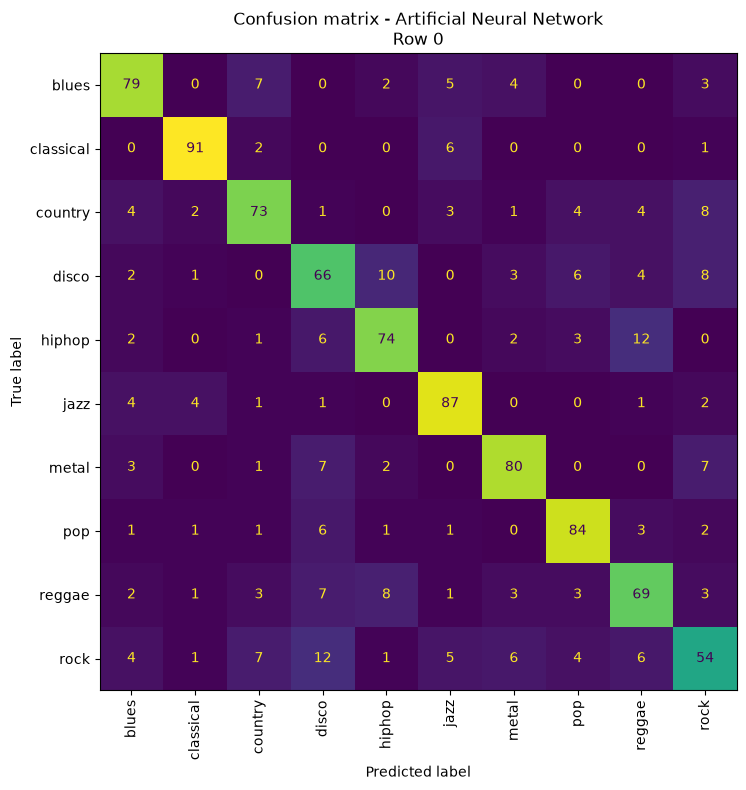

In [10]:

# Seleccionar una fila de la tabla ordenada
num_rows = len(results_df)

print("Select the configuration you want to plot a as a confusion matrix (row number).")
row = int(input(f"Introduce a number between 0 y {num_rows - 1}: "))

if row < 0 or row > num_rows:
    raise ValueError(f"Row number must be between 0 and {num_rows}.")

# Obtener la configuración elegida
selected_row = results_df.iloc[row]
name = selected_row["Algorithm"]
params = selected_row["Parameters"]

print(f"\nSelected algorithm: {name}")
print(f"Parameters: {params}")
print(f"CV accuracy: {selected_row['CV accuracy']:.4f}")
print(f"Overfitting gap: {selected_row['Overfitting gap']:.4f}")

# Reconstruir el pipeline con los parámetros seleccionados
pipeline, _ = models[name]
selected_model = clone(pipeline)
selected_model.set_params(**params)

# Obtener predicciones out-of-fold mediante validación cruzada.
# Cada muestra se predice con un modelo que no la ha utilizado para entrenar.
y_pred = cross_val_predict(
    selected_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

# Matriz de confusión
classes = np.unique(y)

cm = confusion_matrix(y, y_pred, labels=classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    values_format="d",
    colorbar=False
)

ax.set_title(f"Confusion matrix - {name}\nRow {row}")
plt.tight_layout()
plt.show()
